# **Nivel 3 — Investigación (variantes 21–30, máximo 10 puntos)**

**Parte general:** formular una hipótesis, realizar un experimento, comparar Word2Vec con alternativas modernas (FastText, sentence-transformers / rubert-tiny2) y/o investigar en profundidad los factores que influyen en la visualización. Los resultados deben ser reproducibles y las conclusiones deben estar fundamentadas.

**Variante 22 — Embeddings estáticos frente a contextuales**

Obtener vectores para los mismos tokens mediante sentence-transformers, utilizando el modelo **cointegrated/rubert-tiny2**, y visualizarlos junto a los de Word2Vec. Explicar por qué los modelos contextuales producen una geometría diferente.

rubert-tiny2 es un modelo BERT compacto para ruso que proporciona representaciones vectoriales de oraciones de calidad, con una dimensionalidad de **312**.

Modelo: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2).



# hipotesis:

debido a que el modelo word2vec se entrena con el contenido del texto dado, su rendimiento dependera fuertemente de que tan grande y completo sea el texto dado a diferencia de rubert-tiny2 que es un modelo preentrenado que no depende del texto dado. debido a que el textoa usar ahora es gigantesco, no deberia de verse una gran diferencia

## Lematización

La lematización está definida en este cuaderno y se ejecuta en CPU. Convertimos a minúsculas, extraemos palabras rusas y obtenemos el primer lema propuesto por pymorphy3. No filtramos palabras vacías ni aplicamos un mínimo de tres letras. El analizador se reutiliza y `lru_cache` evita repetir análisis durante la sesión.


In [18]:
import polars as pl
import re
import pymorphy3
from functools import lru_cache

# Usamos solo las primeras 10 000 reseñas.
df = pl.read_ndjson("texts/kinopoisk.jsonl", n_rows=10_000)
print(f"Reseñas seleccionadas: {df.height:,}")
datos = df.select("content")

morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=100_000)
def obtener_lema(palabra):
    return morph.parse(palabra)[0].normal_form

def lematizar(texto):
    palabras = re.findall(r"[а-яё]+", texto.lower())
    return [obtener_lema(palabra) for palabra in palabras]

datos = datos.with_columns(
    pl.col("content")
    .fill_null("")
    .map_elements(lematizar, return_dtype=pl.List(pl.String))
    .alias("lemmas")
)

datos.select("content", "lemmas").head()


Reseñas seleccionadas: 10,000


content,lemmas
str,list[str]
""" ""Блеф» — одна из моих самых л…","[""блеф"", ""один"", … ""из""]"
""" Адриано Челентано продолжает …","[""адриано"", ""челентано"", … ""подняться""]"
""" Несомненно, это один из велик…","[""несомненно"", ""это"", … ""из""]"
""" Эта фраза на мой взгляд отраж…","[""этот"", ""фраза"", … ""посмотреть""]"
""" - как пела Земфира, скорее вс…","[""как"", ""петь"", … ""из""]"


## Vectorización con Word2Vec

Gensim utiliza CPU y permite varios hilos. Esto acelera el entrenamiento, pero la ejecución multihilo no garantiza resultados idénticos, incluso con `seed=42`. Para una reproducción estricta, usar `workers=1` y fijar `PYTHONHASHSEED` antes de iniciar Python.


In [19]:
import os
import logging
from gensim.models import Word2Vec

#logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")
#workers = max(1, min(8, (os.cpu_count() or 2) - 1))
#print(f"Entrenando Word2Vec en CPU con {workers} hilos.")

modelo_w2v = Word2Vec(
    sentences=datos['lemmas'].to_list(),
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    epochs=30,
    #workers=workers,
    seed=42
)



In [20]:
modelo_w2v.scan_vocab("привет")

(6, 6)

# Vectorizacion con ruber-tiny2

## Vectores para la comparación visual

Recorremos el vocabulario de Word2Vec en su orden por frecuencia, conservamos las palabras de al menos tres letras y elegimos las primeras 100 que cumplen esa condición. El filtro es solo de longitud, sin lista de palabras vacías. Esta selección afecta a la visualización, no al corpus de entrenamiento. Ambos modelos representan exactamente las mismas palabras, en el mismo orden.

RuBERT recibe cada palabra aislada. Es una comparación inicial entre modelos; todavía no mide cómo cambia una palabra en distintas oraciones.


In [21]:
from sentence_transformers import SentenceTransformer

N_PALABRAS = 100
# Primero filtramos por longitud; después tomamos las primeras 100.
# Se conserva el orden por frecuencia del vocabulario.
palabras = [
    palabra for palabra in modelo_w2v.wv.index_to_key
    if len(palabra) > 3
][:N_PALABRAS]
vectores_w2v = modelo_w2v.wv[palabras]

modelo_rubert = SentenceTransformer(
    "rubert-tiny2", device="cpu", local_files_only=True
)
vectores_rubert = modelo_rubert.encode(
    palabras,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print("Word2Vec:", vectores_w2v.shape)
print("RuBERT:", vectores_rubert.shape)


Loading weights: 100%|██████████| 55/55 [00:00<00:00, 11000.27it/s]
[transformers] BertModel LOAD REPORT from: rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 4/4 [00:00<00:00, 226.21it/s]

Word2Vec: (100, 100)
RuBERT: (100, 312)


## Visualización con t-SNE

Transformamos los vectores de cada modelo a dos coordenadas. Usamos distancia coseno, la misma semilla y los mismos parámetros en ambas proyecciones. La normalización L2 se aplica a ambos conjuntos antes de proyectar.

Las proyecciones se calculan por separado: los ejes, la orientación, la escala y las posiciones no están alineados entre gráficos. Comparamos principalmente vecindades locales. La separación de grupos lejanos no demuestra una distancia semántica equivalente. La misma semilla no garantiza que ambos modelos deban producir la misma disposición.


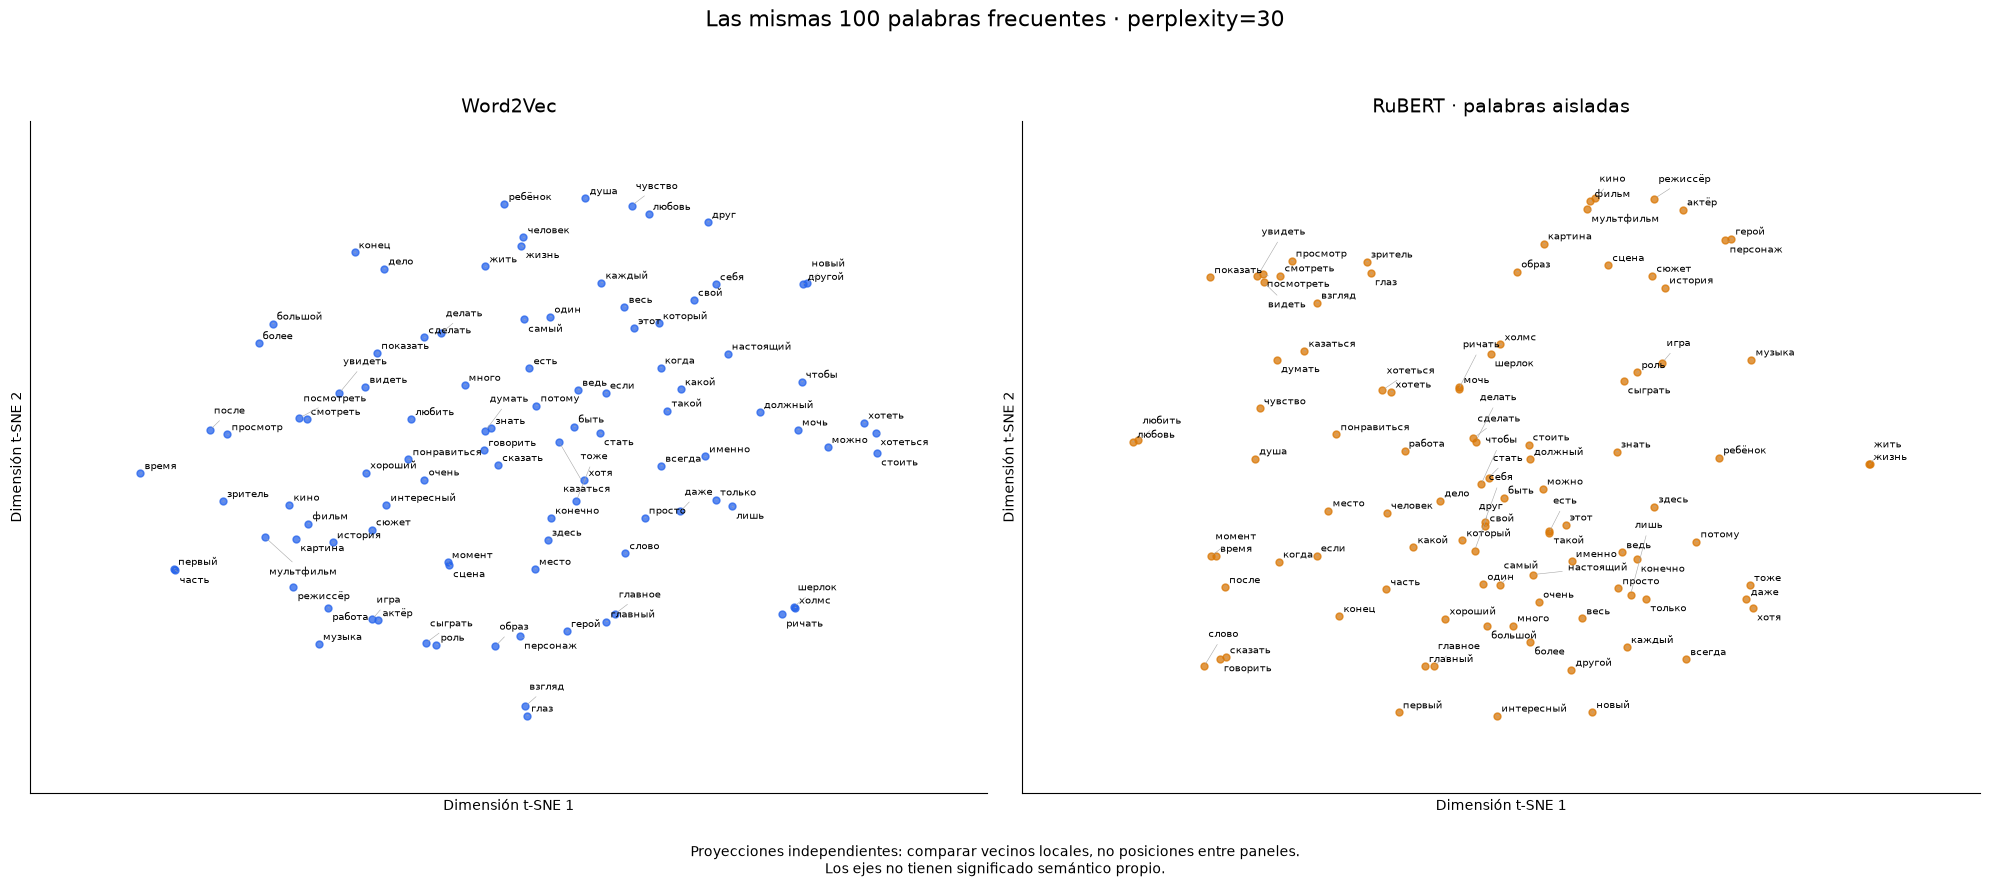

In [22]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

n = len(palabras)
if n < 2:
    raise ValueError("Se necesitan al menos dos palabras para comparar.")
if len(vectores_w2v) != n or len(vectores_rubert) != n:
    raise ValueError("Las matrices deben tener una fila por palabra y el mismo orden.")

# Perplexity debe ser menor que el número de puntos.
perplexity = min(30.0, (n - 1) / 3)

def proyectar_tsne(vectores):
    """Proyecta una matriz de embeddings a dos dimensiones."""
    vectores = normalize(np.asarray(vectores), norm="l2")
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        metric="cosine",
        init="pca",
        learning_rate="auto",
        max_iter=1_000,
        random_state=42
    ).fit_transform(vectores)

posiciones_w2v = proyectar_tsne(vectores_w2v)
posiciones_rubert = proyectar_tsne(vectores_rubert)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, posiciones, titulo, color in [
    (axes[0], posiciones_w2v, "Word2Vec", "#2563eb"),
    (axes[1], posiciones_rubert, "RuBERT · palabras aisladas", "#d97706")
]:
    ax.scatter(posiciones[:, 0], posiciones[:, 1], s=25, color=color, alpha=0.75)
    for palabra, (x, y) in zip(palabras, posiciones):
        ax.annotate(palabra, (x, y), xytext=(3, 3),
                    textcoords="offset points", fontsize=7,
                    arrowprops={"arrowstyle": "-", "color": "0.65", "lw": 0.4})
    ax.set_title(titulo, fontsize=14)
    ax.set_xlabel("Dimensión t-SNE 1")
    ax.set_ylabel("Dimensión t-SNE 2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.margins(0.15)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Las mismas {n} palabras frecuentes · perplexity={perplexity:g}", fontsize=16)
fig.text(0.5, 0.02,
         "Proyecciones independientes: comparar vecinos locales, no posiciones entre paneles.\n"
         "Los ejes no tienen significado semántico propio.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.07, 1, 0.94))
# Desplazamos solo las etiquetas para reducir solapamientos; los puntos no cambian.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax in axes:
    ocupados = []
    for etiqueta in ax.texts:
        for dx in (3, -35, 25):
            libre = False
            for dy in (3, 12, -9, 21, -18, 30, -27, 39, -36, 48, -45):
                etiqueta.set_position((dx, dy))
                caja = plt.Text.get_window_extent(etiqueta, renderer).expanded(1.05, 1.15)
                if not any(caja.overlaps(otra) for otra in ocupados):
                    libre = True
                    break
            if libre:
                break
        ocupados.append(caja)
Path("resultados").mkdir(exist_ok=True)
fig.savefig("resultados/tsne_comparacion.png", dpi=180, bbox_inches="tight")
plt.show()


viendo los graficos podemos ver claras diferencias entre ambos modelos, por ejemplo para время/момент en el caso de rubert se encuentran juntos, en el caso de word2vec se encuentran separados. pero tambien se ven similitudes como большой/более o посмотреть/смотреть/увидеть/показать.. que en ambos casos se encuentran casi a la misma distancia y agrupados. esto se puede deber a la facilidad de algunas palabras a ser usadas en contextos diferentes, por ejemplo персонаж/герой son palabras que se suelen usar en el mismo contexto, mientras que первый o момент pueden usarse tanto juntos como separados siendo первый usado en mas contextos diferentes.